# 04 · Feature engineering: fires upwind, a stagnant lid, recent pollution, the calendar

<a href="https://colab.research.google.com/github/FarhanRajputFelix/saans/blob/main/notebooks/04_features.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Input:** the cleaned master table, cleaned fires, and the LLM event calendar. **Output:** `data/processed/features.parquet` with the forecast targets and four groups of features.

**One rule above all: no peeking into the future.** Every feature for hour *t* uses only what is known at *t*: past PM2.5, weather observed up to *t*, fires already detected, events already announced. Using tomorrow's actual weather would inflate the scores; a real deployment would plug in a weather *forecast* there, which is listed as future work.

**Setup.** Runs the same way locally and in Google Colab. In Colab it clones the repo (which includes the cleaned data) and reads API keys from Colab's *Secrets* panel (key icon on the left).

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules:
    if not os.path.exists("/content/saans"):
        subprocess.run(["git", "clone", "-q", "https://github.com/FarhanRajputFelix/saans.git", "/content/saans"], check=True)
    os.chdir("/content/saans")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm", "shap", "python-dotenv"], check=True)
    from google.colab import userdata
    for k in ["OPENAQ_API_KEY", "FIRMS_MAP_KEY", "GEMINI_API_KEY", "GROQ_API_KEY"]:
        try:
            os.environ[k] = userdata.get(k)
        except Exception:
            pass
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # work from the repo root so `saans` and `data/` resolve
sys.path.insert(0, os.getcwd())

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from saans.config import CITIES, PROCESSED, REPORTS
from saans import viz

viz.use_style()
pd.set_option("display.width", 160)
FIG = REPORTS / "figures"

m = pd.read_parquet(PROCESSED / "master_hourly.parquet").sort_values(["city", "time_utc"]).reset_index(drop=True)
fires = pd.read_parquet(PROCESSED / "fires_clean.parquet")
cal = pd.read_parquet(PROCESSED / "event_calendar.parquet")
TRAIN_END = pd.Timestamp("2024-09-28", tz="UTC")  # targets of training rows end before the 2024 test season
is_train = (m.time_utc < TRAIN_END) & ~m.is_test_season
print(m.shape, "| training rows:", int(is_train.sum()))

(266760, 29) | training rows: 207840


## Targets

AQI is defined on 24-hour means, so the targets are 24-hour means too:
* `target_24h`: mean PM2.5 over the **next 24 hours** (t+1 to t+24);
* `target_48h`: mean PM2.5 over **the 24 hours after that** (t+25 to t+48);
* `hazard_24h`: whether `target_24h` reaches **225.5 ug/m3** (AQI above 300).

A 24-hour mean needs at least 18 of its 24 hours (75% completeness), the same rule used in cleaning.

In [3]:
g = m.groupby("city")
m["pm25_24h"] = g.pm25.transform(lambda s: s.rolling(24, min_periods=18).mean())
m["target_24h"] = m.groupby("city").pm25_24h.shift(-24)
m["target_48h"] = m.groupby("city").pm25_24h.shift(-48)
m["hazard_24h"] = (m.target_24h >= 225.5).astype(float).where(m.target_24h.notna())
m.groupby("city")[["target_24h", "hazard_24h"]].agg(["count", "mean"]).round(3)

target_24h          hazard_24h       
                count     mean      count   mean
city                                            
faisalabad       5309  145.688       5309  0.272
islamabad       44251   55.480      44251  0.002
karachi         36467   48.207      36467  0.000
lahore          41460  119.105      41460  0.155
multan           5477  124.469       5477  0.219

## Group 1 · Recent pollution

PM2.5 at 1, 3, 6, 24 and 48 hours before *t*, the 24-hour mean and maximum, and the 24-hour trend. Smog builds over days, so recent pollution is the strongest single clue (and `pm25_24h` alone is the persistence baseline every model must beat).

In [4]:
g = m.groupby("city")
for h in [1, 3, 6, 24, 48]:
    m[f"pm25_lag{h}h"] = g.pm25.shift(h)
m["pm25_now"] = m.pm25
m["pm25_max24h"] = g.pm25.transform(lambda s: s.rolling(24, min_periods=18).max())
m["pm25_trend24h"] = m.pm25_24h - g.pm25_24h.shift(24)
RECENT = ["pm25_now", "pm25_lag1h", "pm25_lag3h", "pm25_lag6h", "pm25_lag24h", "pm25_lag48h", "pm25_24h", "pm25_max24h", "pm25_trend24h"]

## Group 2 · Weather and the Stagnation Index

* Wind as **u/v components** (east-west and north-south), because direction is circular: 359 degrees and 1 degree are neighbours, and a model cannot learn that from the raw angle.
* **Ventilation coefficient** = boundary layer height x wind speed (m2/s): how fast the city's air is flushed.
* 24-hour means of the key variables, 24-hour rain, 24-hour pressure change.
* **Stagnation Index**: the average of three standardized signals, *low ventilation*, *high humidity* and *cold air*, over the past 24 hours. Standardization uses training-period statistics only.

In [5]:
rad = np.radians
for lvl in ["10m", "100m"]:
    ws, wd = m[f"wind_speed_{lvl}"], rad(m[f"wind_direction_{lvl}"])
    m[f"u_{lvl}"], m[f"v_{lvl}"] = -ws * np.sin(wd), -ws * np.cos(wd)  # direction is where wind comes FROM
m["dewpoint_depression"] = m.temperature_2m - m.dew_point_2m
m["ventilation"] = m.boundary_layer_height * m.wind_speed_10m
g = m.groupby("city")
roll = lambda col, f="mean": g[col].transform(lambda s: getattr(s.rolling(24, min_periods=12), f)())
m["ventilation_24h"] = roll("ventilation")
m["blh_24h"] = roll("boundary_layer_height")
m["rh_24h"] = roll("relative_humidity_2m")
m["temp_24h"] = roll("temperature_2m")
m["wind_24h"] = roll("wind_speed_10m")
m["rain_24h"] = roll("precipitation", "sum")
m["pressure_change24h"] = m.surface_pressure - g.surface_pressure.shift(24)

STAG_STATS = {}  # training mean and std of each signal, saved so the live forecast uses identical scaling
def z(col, sign=1.0):
    x = sign * m[col]
    mu, sd = float(x[is_train].mean()), float(x[is_train].std())
    STAG_STATS[col] = {"sign": sign, "mean": mu, "std": sd}
    return (x - mu) / sd
m["log_vent_24h"] = np.log1p(m.ventilation_24h)
m["stagnation_index"] = (z("log_vent_24h", -1) + z("rh_24h") + z("temp_24h", -1)) / 3
WEATHER = ["temperature_2m", "relative_humidity_2m", "dewpoint_depression", "precipitation", "surface_pressure", "cloud_cover",
           "wind_speed_10m", "u_10m", "v_10m", "u_100m", "v_100m", "shortwave_radiation", "boundary_layer_height",
           "ventilation", "ventilation_24h", "blh_24h", "rh_24h", "temp_24h", "wind_24h", "rain_24h",
           "pressure_change24h", "stagnation_index"]

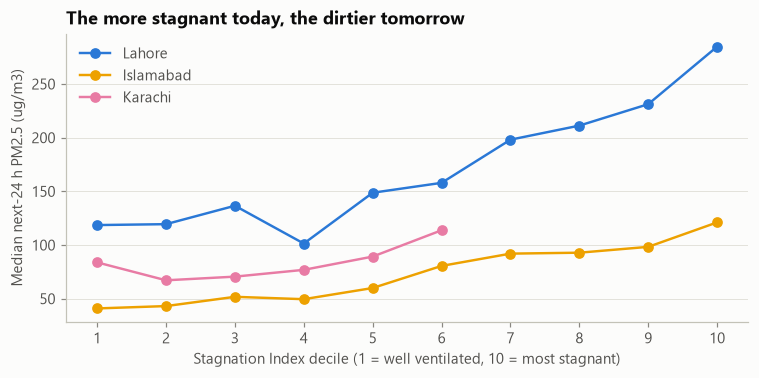

In [6]:
season = is_train & m.time_utc.dt.month.isin([10, 11, 12, 1]) & m.target_24h.notna()
bins = m[season].assign(si_bin=pd.qcut(m.loc[season, "stagnation_index"], 10, labels=False))
fig, ax = plt.subplots(figsize=(8, 3.4))
for city in ["lahore", "islamabad", "karachi"]:
    s = bins[bins.city == city].groupby("si_bin").target_24h.median()
    ax.plot(s.index + 1, s.values, marker="o", color=viz.CITY_COLORS[city], label=CITIES[city].name)
ax.set(title="The more stagnant today, the dirtier tomorrow", xlabel="Stagnation Index decile (1 = well ventilated, 10 = most stagnant)",
       ylabel="Median next-24 h PM2.5 (ug/m3)", xticks=range(1, 11))
ax.legend(loc="upper left")
fig.savefig(FIG / "stagnation_vs_pm25.png", bbox_inches="tight")
plt.show()

## Group 3 · The Upwind Fire Exposure Index (UFI)

For each city and hour *t*, sum over every crop fire detected **24 to 72 hours earlier**:

$$UFI(t) = \sum_{i} FRP_i \cdot e^{-d_i / L} \cdot \max(0, \cos\theta_i)$$

* $FRP_i$: the fire's radiative power (MW), from NASA;
* $d_i$: its distance from the city (km), with decay length $L$;
* $\theta_i$: the angle between the direction the city's wind was coming **from** (100 m wind, at the hour the fire was seen) and the bearing from the city to the fire. If the wind blows from the fire towards the city, $\cos\theta = 1$; crosswind or downwind fires count zero.

A second version over the **last 24 hours** captures nearby fires whose smoke arrives faster.

**Tuning L on training data only.** We compute the UFI for several values of $L$, with and without the wind term, and keep the version that correlates best (Spearman) with next-day PM2.5 in the training smog seasons.

In [7]:
def bearing_deg(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    x = np.sin(lon2 - lon1) * np.cos(lat2)
    y = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(lon2 - lon1)
    return (np.degrees(np.arctan2(x, y)) + 360) % 360

def dist_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

city_fires = {}
for c in CITIES.values():
    d = dist_km(c.lat, c.lon, fires.latitude.to_numpy(), fires.longitude.to_numpy())
    f = fires[d <= 600].assign(d_km=d[d <= 600])
    f["bearing"] = bearing_deg(c.lat, c.lon, f.latitude.to_numpy(), f.longitude.to_numpy())
    wind = m.loc[m.city == c.slug, ["time_utc", "wind_direction_100m"]].rename(columns={"time_utc": "hour_utc"})
    f = f.merge(wind, on="hour_utc", how="left")
    f["upwind"] = np.clip(np.cos(np.radians(f.bearing - f.wind_direction_100m)), 0, None).fillna(0)
    city_fires[c.slug] = f

def ufi(L: float, use_wind: bool = True, window=(24, 72)) -> pd.Series:
    out = []
    for slug, f in city_fires.items():
        w = f.frp * np.exp(-f.d_km / L) * (f.upwind if use_wind else 1.0)
        hourly = w.groupby(f.hour_utc).sum()
        times = m.loc[m.city == slug, "time_utc"]
        s = hourly.reindex(times.to_numpy(), fill_value=0.0)
        lo, hi = window
        s = s.rolling(hi - lo + 1, min_periods=1).sum().shift(lo)
        out.append(pd.Series(s.to_numpy(), index=times.index))
    return pd.concat(out).sort_index()

rows = []
for L in [25, 50, 100, 200, 400]:
    for use_wind in [True, False]:
        u = ufi(L, use_wind)
        rows.append({"L_km": L, "wind_weighted": use_wind,
                     "spearman_with_next_24h_pm25": round(u[season].corr(m.loc[season, "target_24h"], method="spearman"), 3)})
tuning = pd.DataFrame(rows)
tuning.pivot(index="L_km", columns="wind_weighted", values="spearman_with_next_24h_pm25")

wind_weighted,False,True
L_km,,
25,0.298,0.351
50,0.294,0.382
100,0.234,0.365
200,0.211,0.358
400,0.200,0.355


In [8]:
best = tuning.sort_values("spearman_with_next_24h_pm25", ascending=False).iloc[0]
L_BEST = float(best.L_km)
wind_gain = (tuning[tuning.wind_weighted].set_index("L_km").spearman_with_next_24h_pm25
             - tuning[~tuning.wind_weighted].set_index("L_km").spearman_with_next_24h_pm25)
print(f"Best decay length L = {L_BEST:.0f} km (wind-weighted: {bool(best.wind_weighted)}); "
      f"wind weighting changes the correlation by {wind_gain.loc[L_BEST]:+.3f} at that L")
m["ufi_24_72h"] = ufi(L_BEST, True, (24, 72))
m["ufi_0_24h"] = ufi(L_BEST, True, (0, 23))
m["fires_300km_72h"] = m.groupby("city").fires_300km.transform(lambda s: s.rolling(72, min_periods=1).sum())
FIRES = ["ufi_24_72h", "ufi_0_24h", "fires_300km_72h"]

Best decay length L = 50 km (wind-weighted: True); wind weighting changes the correlation by +0.088 at that L


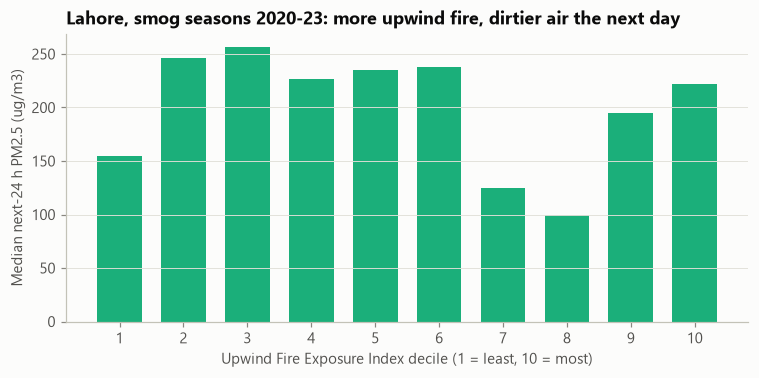

In [9]:
lh = m[season & (m.city == "lahore")].copy()
lh["ufi_bin"] = pd.qcut(lh.ufi_24_72h.rank(method="first"), 10, labels=False) + 1
s = lh.groupby("ufi_bin").target_24h.median()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(s.index, s.values, color=viz.SERIES[2], width=0.7)
ax.set(title="Lahore, smog seasons 2020-23: more upwind fire, dirtier air the next day",
       xlabel="Upwind Fire Exposure Index decile (1 = least, 10 = most)", ylabel="Median next-24 h PM2.5 (ug/m3)", xticks=range(1, 11))
fig.savefig(FIG / "ufi_vs_pm25_lahore.png", bbox_inches="tight")
plt.show()

## Group 4 · Calendar and events

Hour of day and day of week (Pakistan time), month, a smooth day-of-year cycle, the rice-stubble (Oct-Nov) and wheat-stubble (Apr-May) burning windows, and the event calendar from notebook 03: active smog measures, crop-burning bans and fireworks nights. Events are matched on the Pakistan-time date and are known at forecast time because they were announced in the news.

In [10]:
local = m.time_pkt.dt.tz_localize(None)
m["hour_pkt"] = local.dt.hour
m["day_of_week"] = local.dt.day_of_week
m["month"] = local.dt.month
doy = local.dt.day_of_year
m["doy_sin"], m["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
m["rice_burning_window"] = local.dt.month.isin([10, 11]).astype(int)
m["wheat_burning_window"] = (((local.dt.month == 4) & (local.dt.day >= 15)) | (local.dt.month == 5)).astype(int)
m["date"] = local.dt.floor("D")
# the calendar's fireworks flag (fixed dates + LLM-found nights) replaces the cleaning tag of the same name
m = m.drop(columns=["fireworks_night"], errors="ignore").merge(cal, on=["city", "date"], how="left")
for col in ["measures_active", "crop_burning_ban_active", "fireworks_night"]:
    m[col] = m[col].fillna(0)
CALENDAR = ["hour_pkt", "day_of_week", "month", "doy_sin", "doy_cos", "rice_burning_window", "wheat_burning_window",
            "measures_active", "crop_burning_ban_active", "fireworks_night"]

## Save

City identity is deliberately **not** a feature: the model must learn from physics and recent pollution, so that it can forecast Faisalabad and Multan, cities absent from training.

In [11]:
GROUPS = {"Recent pollution": RECENT, "Weather": WEATHER, "Upwind fires": FIRES, "Calendar": CALENDAR}
keep = ["city", "time_utc", "time_pkt", "is_test_season", "pm25", "pm25_source", "target_24h", "target_48h", "hazard_24h"]
feat = m[keep + sum(GROUPS.values(), [])]
feat.to_parquet(PROCESSED / "features.parquet", index=False)
(PROCESSED / "feature_groups.json").write_text(json.dumps({"groups": GROUPS, "ufi_L_km": L_BEST, "stagnation_stats": STAG_STATS}, indent=1))
print(f"{feat.shape[0]:,} rows x {sum(len(v) for v in GROUPS.values())} features in {len(GROUPS)} groups")
pd.Series({k: len(v) for k, v in GROUPS.items()}, name="features")

266,760 rows x 44 features in 4 groups


Recent pollution     9
Weather             22
Upwind fires         3
Calendar            10
Name: features, dtype: int64